# Deblurring con difusión — Entrega 2
**Proyecto IA II · UIS** · Repo: [Serreneitor206/Deblurring-Diffusion-IA2](https://github.com/Serreneitor206/Deblurring-Diffusion-IA2)

**Integrantes:** Santiago Ardila, María Rodríguez, Juan Serrano

Método basado en Whang et al., *Deblurring via Stochastic Refinement* (CVPR 2022), en dos etapas:

| Etapa | Qué hace | Estado |
|---|---|---|
| 1. Predictor | **NAFNet-64** (pesos oficiales GoPro) + *fine-tuning* en el GoPro de Kaggle → predicción $\hat{y}$ | ✅ lista |
| 2. Refinador | **DDPM condicional** que aprende el residuo $r = x - \hat{y}$, condicionado en $[y, \hat{y}]$, con muestreo truncado desde $\hat{y}$ ruidoso | 🛠️ en implementación (entrega final) |

Este notebook trae el código del repo de GitHub a Colab y reproduce los resultados de la entrega 2:

1. Preparación del entorno (GPU, repo, pesos, dataset)
2. Diagnóstico del dataset
3. Fine-tuning de NAFNet-64
4. Evaluación en el **test**: borrosa vs NAFNet sin FT vs NAFNet con FT
5. Comparación con los intentos anteriores (DDPM v2 desde ruido y zero-shot DeblurSDI)
6. Resultados cualitativos
7. Próximos pasos


## 1. Preparación del entorno

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch
print("PyTorch", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())

name, memory.total [MiB]
Tesla T4, 15360 MiB
PyTorch 2.11.0+cu130 | CUDA disponible: True


### 1.1 Clonación el repositorio
Los pesos del fine-tuning (`checkpoints/nafnet_ft/best.pth`, ~272 MB) están en **Git LFS**.
Se clona el historial completo porque la sección 5 lee de commits anteriores las salidas guardadas de DDPM v2 y del zero-shot.

In [ ]:
REPO_URL = "https://github.com/Serreneitor206/Deblurring-Diffusion-IA2.git"
REPO_DIR = "/content/Deblurring-Diffusion-IA2"

!git lfs install --skip-repo -q
import os
if not os.path.isdir(REPO_DIR):
    !GIT_LFS_SKIP_SMUDGE=1 git clone -q {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!git lfs pull --include="checkpoints/nafnet_ft/best.pth"
!git log --oneline -n 6
!ls -la . checkpoints/nafnet_ft

git: 'lfs' is not a git command. See 'git --help'.

The most similar command is
	log
/content/Deblurring-Diffusion-IA2
git: 'lfs' is not a git command. See 'git --help'.

The most similar command is
	log
783e465 (HEAD -> main, origin/main, origin/HEAD) NAFNet-64 con fine-tuning en GoPro + checkpoints
0ce381e segunda version, principios entrenamiento, no zeroshot
6ce6d78 Código deblurring sin pesos del modelo
e601734 Initial commit
.:
total 80
drwxr-xr-x 4 root root  4096 Nov  2 15:28 .
drwxr-xr-x 1 root root  4096 Nov  2 15:28 ..
drwxr-xr-x 3 root root  4096 Nov  2 15:28 checkpoints
-rw-r--r-- 1 root root   311 Nov  2 15:28 config.py
-rw-r--r-- 1 root root  3657 Nov  2 15:28 diagnose_dataset.py
-rw-r--r-- 1 root root 12099 Nov  2 15:28 finetune_nafnet.py
drwxr-xr-x 8 root root  4096 Nov  2 15:28 .git
-rw-r--r-- 1 root root    83 Nov  2 15:28 .gitattributes
-rw-r--r-- 1 root root   796 Nov  2 15:28 .gitignore
-rw-r--r-- 1 root root  8661 Nov  2 15:28 nafnet_arch.py
-rw-r--r-- 1 root roo

### 1.2 Verificación de los pesos del fine-tuning
Si `best.pth` pesa unos pocos bytes es un **puntero LFS**.
En ese caso, subir `best.pth` a Google Drive y poner su ruta en `FT_WEIGHTS_DRIVE`.

In [ ]:
FT_WEIGHTS = "checkpoints/nafnet_ft/best.pth"
FT_WEIGHTS_DRIVE = "/content/drive/MyDrive/IA 2/Proyecto IA2/best.pth" # Solo se usa si LFS falla

def es_puntero_lfs(p):
    return (not os.path.isfile(p)) or os.path.getsize(p) < 10_000

if es_puntero_lfs(FT_WEIGHTS):
    print("best.pth es un puntero LFS -> intentando desde Google Drive")
    from google.colab import drive
    drive.mount("/content/drive")
    assert os.path.isfile(FT_WEIGHTS_DRIVE), f"No encontré {FT_WEIGHTS_DRIVE}"
    FT_WEIGHTS = FT_WEIGHTS_DRIVE
print(f"Pesos FT: {FT_WEIGHTS}  ({os.path.getsize(FT_WEIGHTS) / 1e6:.1f} MB)")

best.pth es un puntero LFS -> intentando desde Google Drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pesos FT: /content/drive/MyDrive/IA 2/Proyecto IA2/best.pth  (271.7 MB)


### 1.3 Instalación de dependencias

In [ ]:
!pip -q install gdown scikit-image kagglehub

### 1.4 Dataset: GoPro de Kaggle
[`adwythdarsanr/gopro-image-deblurring-dataset`](https://www.kaggle.com/datasets/adwythdarsanr/gopro-image-deblurring-dataset)


*   2 103 pares de train y 1 111 de test, 1280×720.
* Se descarga con `kagglehub` al disco temporal de Colab. (No es el oficial)




In [ ]:
try:
    from google.colab import userdata
    for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
except ImportError:
    pass

import kagglehub
ds_path = kagglehub.dataset_download("adwythdarsanr/gopro-image-deblurring-dataset")

def buscar_data_root(base):
    # Carpeta que contenga train/ y test/ (con blur/ y sharp/ adentro)
    for root, dirs, _ in os.walk(base):
        low = {d.lower(): d for d in dirs}
        if "train" in low and "test" in low and \
           os.path.isdir(os.path.join(root, low["test"], "blur")):
            return root
    raise FileNotFoundError(f"No encontré train/ y test/ dentro de {base}")

DATA_ROOT = buscar_data_root(ds_path)
os.environ["GOPRO_PATH"] = DATA_ROOT # config.py lo lee como ruta por defecto
for s in ("train", "test"):
    d = os.path.join(DATA_ROOT, s)
    print(s, {sub: len(os.listdir(os.path.join(d, sub))) for sub in ("blur", "sharp")})
print("DATA_ROOT =", DATA_ROOT)

100%|██████████| 6.08G/6.08G [01:15<00:00, 86.3MB/s]

Extracting files...


train {'blur': 2103, 'sharp': 2103}
test {'blur': 1111, 'sharp': 1111}
DATA_ROOT = /root/.cache/kagglehub/datasets/adwythdarsanr/gopro-image-deblurring-dataset/versions/1/Gopro


## 2. Diagnóstico del dataset
El GoPro de Kaggle **no es idéntico** al GoPro original (frames renombrados a `0.png, 1.png, …` y procesado distinto).
`diagnose_dataset.py` revisa formato, brillo blur vs sharp (¿`blur` o `blur_gamma`?) y artefactos de JPEG.

In [ ]:
!python diagnose_dataset.py --data_root "{DATA_ROOT}" --n 40


=== train: 2103 pares, muestra 40
  extension: .png | resoluciones: {(720, 1280, 3)}
  tamano medio blur: 0.91 MB
  brillo blur - sharp (niveles 0-255): media +2.20, positivo en 100% de las imagenes
  idem en zonas brillantes (top 10%): -8.16
  indice de bloques 8x8: blur 1.038 | sharp 1.064

=== test: 1111 pares, muestra 40
  extension: .png | resoluciones: {(720, 1280, 3)}
  tamano medio blur: 1.01 MB
  brillo blur - sharp (niveles 0-255): media +1.81, positivo en 100% de las imagenes
  idem en zonas brillantes (top 10%): -6.76
  indice de bloques 8x8: blur 1.035 | sharp 1.074


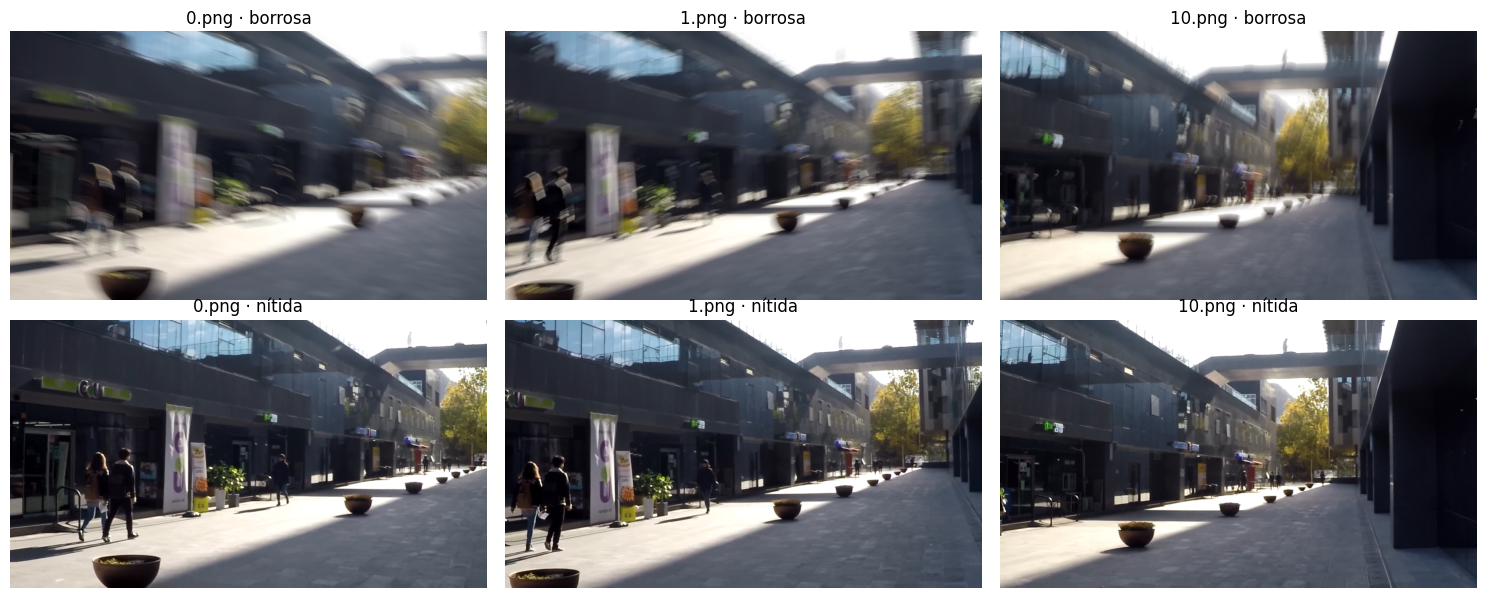

In [ ]:
import cv2, glob, matplotlib.pyplot as plt
test_blur = sorted(glob.glob(os.path.join(DATA_ROOT, "test", "blur", "*.png")))[:3]
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j, bp in enumerate(test_blur):
    sp = bp.replace(os.sep + "blur" + os.sep, os.sep + "sharp" + os.sep)
    for i, (p, t) in enumerate(((bp, "borrosa"), (sp, "nítida"))):
        ax[i, j].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        ax[i, j].set_title(f"{os.path.basename(p)} · {t}"); ax[i, j].axis("off")
plt.tight_layout(); plt.show()

## 3. Etapa 1 - Fine-tuning de NAFNet-64
Configuración (`finetune_nafnet.py`): 20k iteraciones, parches 256, batch 2, LR 3e-5 con coseno y warmup de 500, fp16 + gradient checkpointing. Validación cada 2k iteraciones sobre 40 imágenes de ~10 % de las
**escenas** del train (split por secuencia, sin fuga entre escenas).


Train: 1788 pares | Val: 315 pares (3 escenas)


,iter,val_psnr,lr
0,0,29.204545,0.000000e+00
1,2000,34.464105,2.956616e-05
2,4000,34.811502,2.768688e-05
3,6000,34.935589,2.450692e-05
4,8000,34.995922,2.035360e-05
5,10000,35.063357,1.565438e-05
6,12000,35.084132,1.089296e-05
7,14000,35.102710,6.559414e-06
8,16000,35.116633,3.099778e-06
9,18000,35.120040,8.701431e-07


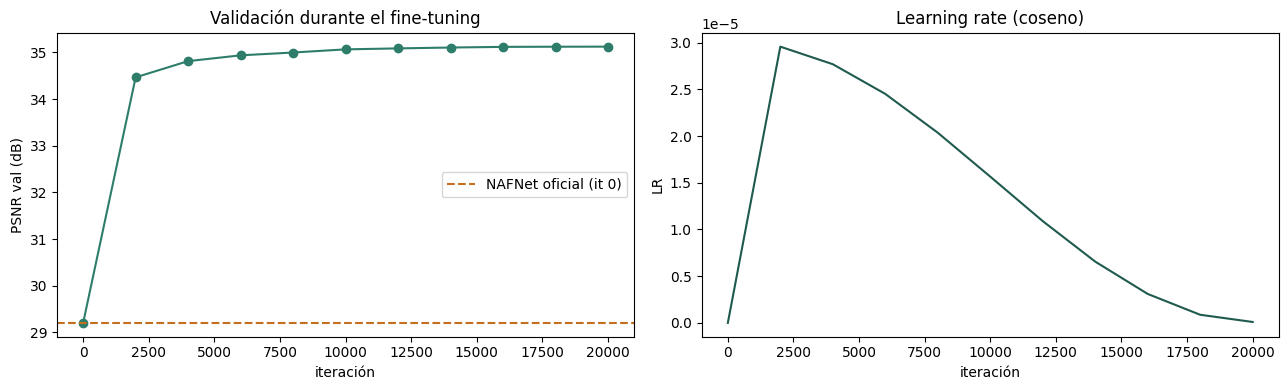

Val PSNR: 29.20 -> 35.12 dB (+5.92)


In [ ]:
import json, pandas as pd
log = pd.read_csv("checkpoints/nafnet_ft/log.csv")
split = json.load(open("checkpoints/nafnet_ft/split.json"))
print(f"Train: {len(split['train'])} pares | Val: {len(split['val'])} pares "
      f"({len(split['val_sequences'])} escenas)")
display(log)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(log["iter"], log["val_psnr"], "o-", color="#2e7d6b")
ax[0].axhline(log["val_psnr"].iloc[0], ls="--", color="#c46f1e", label="NAFNet oficial (it 0)")
ax[0].set(xlabel="iteración", ylabel="PSNR val (dB)", title="Validación durante el fine-tuning"); ax[0].legend()
ax[1].plot(log["iter"], log["lr"], color="#1f5a4e")
ax[1].set(xlabel="iteración", ylabel="LR", title="Learning rate (coseno)")
plt.tight_layout(); plt.show()
print(f"Val PSNR: {log.val_psnr.iloc[0]:.2f} -> {log.val_psnr.max():.2f} dB "
      f"(+{log.val_psnr.max() - log.val_psnr.iloc[0]:.2f})")

In [ ]:
REENTRENAR = False
if REENTRENAR:
    !python finetune_nafnet.py --data_root "{DATA_ROOT}" --out_dir ./checkpoints/nafnet_ft_colab --workers 2
    FT_WEIGHTS = "./checkpoints/nafnet_ft_colab/best.pth"

## 4. Evaluación en el test
`eval_comparativa.py` (aún no está en el repo, se escribe aquí) compara **borrosa / NAFNet sin FT / NAFNet con FT**:

1. **PSNR/SSIM en el test completo** a resolución nativa 1280×720 → `metrics_test.csv`, `summary.json`.
2. **Las mismas 10 imágenes que DDPM v2**, redimensionadas a 640×360 → `cualitativo.csv` + imágenes.
3. **Las mismas 5 imágenes del zero-shot**, a 256×256.

Los pesos oficiales de NAFNet (`pretrained/NAFNet-GoPro-width64.pth`) se descargan solos con `gdown`.

In [ ]:
%%writefile eval_comparativa.py
"""
Evaluacion comparativa en el TEST de GoPro:  NAFNet-64 oficial (sin FT)  vs  NAFNet-64 con fine-tuning.

Hace dos cosas:
  1) Metricas en el test completo (o --limit N): PSNR/SSIM de borrosa, NAFNet sin FT y NAFNet con FT,
     a resolucion nativa (1280x720), igual que precompute_nafnet.py.
  2) Material cualitativo sobre las mismas imagenes que usaron los intentos anteriores:
       - DDPM v2  -> primeros 10 pares (sorted() normal), redimensionados a lado max 640  (640x360)
       - Zero-shot -> primeros 5 pares, redimensionados a 256x256
     Guarda borrosa / NAFNet sin FT / NAFNet con FT / nitida a esas resoluciones para armar
     las comparaciones  borrosa | DDPM | NAFNet sin FT | NAFNet con FT | nitida.

Uso (desde la raiz del repo, rama con nafnet_arch.py y precompute_nafnet.py):
    python eval_comparativa.py --data_root /kaggle/input/<dataset>/gopro \
                               --ft_weights checkpoints/nafnet_ft/best.pth
Al final queda  <out_dir>.zip  para descargar.
"""
import argparse
import csv
import glob
import json
import os
import shutil
import time

import cv2
import numpy as np
import torch
from tqdm import tqdm

from nafnet_arch import build_nafnet
from precompute_nafnet import (ensure_weights, find_split_dir, list_pairs, predict,
                               psnr_u8, read_rgb, ssim_u8)


def ddpm_style_pairs(split_dir):
    """Mismo orden que los data_loader de DDPM v2 y zero-shot: sorted() normal, emparejado por nombre."""
    blur = sorted(glob.glob(os.path.join(split_dir, "blur", "*.png")))
    sharp = {os.path.basename(f): f for f in glob.glob(os.path.join(split_dir, "sharp", "*.png"))}
    return [(b, sharp[os.path.basename(b)]) for b in blur if os.path.basename(b) in sharp]


def to_u8(img):
    return np.round(np.clip(img, 0, 1) * 255).astype(np.uint8)


def save_u8(path, img_u8):
    cv2.imwrite(path, cv2.cvtColor(img_u8, cv2.COLOR_RGB2BGR))


def resize_u8(img_u8, size):
    return cv2.resize(img_u8, size)  # INTER_LINEAR, como en los data_loader originales


def size_ddpm(h, w, max_side=640):
    if max(h, w) <= max_side:
        return (w, h)
    s = max_side / max(h, w)
    return (int(w * s), int(h * s))


def psnr8(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def ssim8(a, b):
    from skimage.metrics import structural_similarity
    return float(structural_similarity(a, b, channel_axis=2, data_range=255))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_root", required=True, help="Carpeta con train/ y test/")
    ap.add_argument("--ft_weights", default="checkpoints/nafnet_ft/best.pth")
    ap.add_argument("--base_weights", default="./pretrained/NAFNet-GoPro-width64.pth")
    ap.add_argument("--model", default="NAFNet-GoPro-width64")
    ap.add_argument("--out_dir", default="./eval_comparativa")
    ap.add_argument("--limit", type=int, default=0, help="Solo N imagenes en las metricas (0 = test completo)")
    ap.add_argument("--n_ddpm", type=int, default=10)
    ap.add_argument("--n_zeroshot", type=int, default=5)
    ap.add_argument("--no_ssim", action="store_true")
    ap.add_argument("--skip_metrics", action="store_true", help="Solo genera el material cualitativo")
    args = ap.parse_args()

    if os.path.getsize(args.ft_weights) < 10_000:
        raise SystemExit(f"'{args.ft_weights}' parece un puntero de Git LFS, no los pesos reales. "
                         "Ejecuta 'git lfs pull' o apunta --ft_weights al best.pth de tu output de Kaggle.")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = device.type == "cuda"
    print(f"Dispositivo: {device}" + (f" ({torch.cuda.get_device_name(0)})" if amp else ""))

    ensure_weights(args.base_weights, args.model)
    nets = {"base": build_nafnet(args.model, args.base_weights, tlc=True, device=device),
            "ft": build_nafnet(args.model, args.ft_weights, tlc=True, device=device)}
    state = {}

    def run(net_key, img):
        return predict(nets[net_key], img, device, amp, None, 64, state)

    split_dir = find_split_dir(args.data_root, "test")
    os.makedirs(args.out_dir, exist_ok=True)
    summary = {"model": args.model, "ft_weights": args.ft_weights}

    # 1) Material cualitativo (mismas imagenes que DDPM v2 / zero-shot)
    qpairs = ddpm_style_pairs(split_dir)
    n_q = max(args.n_ddpm, args.n_zeroshot)
    qdir_d = os.path.join(args.out_dir, "ddpm_640")
    qdir_z = os.path.join(args.out_dir, "zeroshot_256")
    os.makedirs(qdir_d, exist_ok=True)
    os.makedirs(qdir_z, exist_ok=True)
    qrows = []
    for i, (bp, sp) in enumerate(tqdm(qpairs[:n_q], desc="cualitativo")):
        blur, sharp = read_rgb(bp), read_rgb(sp)
        preds = {k: run(k, blur) for k in nets}
        imgs = {"blur": to_u8(blur), "sharp": to_u8(sharp),
                "nafnet_base": to_u8(preds["base"]), "nafnet_ft": to_u8(preds["ft"])}
        h, w = blur.shape[:2]
        row = {"idx": i, "name": os.path.basename(bp)}
        # Version DDPM v2 (lado max 640)
        if i < args.n_ddpm:
            sz = size_ddpm(h, w)
            small = {k: resize_u8(v, sz) for k, v in imgs.items()}
            for k, v in small.items():
                save_u8(os.path.join(qdir_d, f"{k}_{i:04d}.png"), v)
            for k in ("blur", "nafnet_base", "nafnet_ft"):
                row[f"psnr640_{k}"] = psnr8(small[k], small["sharp"])
                row[f"ssim640_{k}"] = ssim8(small[k], small["sharp"])
            # Recortes a resolucion nativa, para ver detalle
            for k, v in imgs.items():
                save_u8(os.path.join(qdir_d, f"full_{k}_{i:04d}.png"), v)
        # Version zero-shot(256x256)
        if i < args.n_zeroshot:
            for k, v in imgs.items():
                save_u8(os.path.join(qdir_z, f"{k}_{i:04d}.png"), resize_u8(v, (256, 256)))
        qrows.append(row)
    with open(os.path.join(args.out_dir, "cualitativo.csv"), "w", newline="") as f:
        keys = sorted({k for r in qrows for k in r}, key=lambda k: (k != "idx", k != "name", k))
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(qrows)
    print("Material cualitativo listo.")

    #  2) Metricas en el test
    if not args.skip_metrics:
        pairs = list_pairs(split_dir)
        if args.limit:
            step = max(1, len(pairs) // args.limit)
            pairs = pairs[::step][:args.limit]
        rows, t0 = [], time.time()
        for bp, sp in tqdm(pairs, desc="test"):
            blur, sharp = read_rgb(bp), read_rgb(sp)
            row = {"name": os.path.basename(bp), "psnr_blur": psnr_u8(blur, sharp)}
            if not args.no_ssim:
                row["ssim_blur"] = ssim_u8(blur, sharp)
            for k in nets:
                pred = run(k, blur)
                row[f"psnr_{k}"] = psnr_u8(pred, sharp)
                if not args.no_ssim:
                    row[f"ssim_{k}"] = ssim_u8(pred, sharp)
            rows.append(row)
        with open(os.path.join(args.out_dir, "metrics_test.csv"), "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            w.writeheader()
            w.writerows(rows)
        summary["test"] = {"n": len(rows), "seconds": round(time.time() - t0, 1)}
        for k in rows[0]:
            if k != "name":
                summary["test"][k] = float(np.mean([r[k] for r in rows]))
        t = summary["test"]
        print(f"\nTEST ({t['n']} imagenes)")
        for k, lab in (("blur", "Borrosa"), ("base", "NAFNet sin FT"), ("ft", "NAFNet con FT")):
            s = f"  {lab:14s} PSNR = {t[f'psnr_{k}']:.2f} dB"
            if f"ssim_{k}" in t:
                s += f" | SSIM = {t[f'ssim_{k}']:.4f}"
            print(s)

    with open(os.path.join(args.out_dir, "summary.json"), "w") as f:
        json.dump(summary, f, indent=2)
    zip_path = shutil.make_archive(args.out_dir.rstrip("/"), "zip", args.out_dir)
    print(f"\nListo -> {zip_path}")


if __name__ == "__main__":
    main()

Writing eval_comparativa.py


Prueba rápida con 20 imágenes del test:

In [ ]:
!python eval_comparativa.py --data_root "{DATA_ROOT}" --ft_weights "{FT_WEIGHTS}" \
        --limit 20 --out_dir ./eval_prueba

Dispositivo: cuda (Tesla T4)
Descargando pesos de NAFNet-GoPro-width64 ...
Downloading...
From (original): https://drive.google.com/uc?id=1S0PVRbyTakYY9a82kujgZLbMihfNBLfC
From (redirected): https://drive.google.com/uc?id=1S0PVRbyTakYY9a82kujgZLbMihfNBLfC&confirm=t&uuid=42af42c4-38d2-4e0e-99fe-84c9a11eed04
To: /content/Deblurring-Diffusion-IA2/pretrained/NAFNet-GoPro-width64.pth
100% 272M/272M [00:05<00:00, 48.3MB/s]
cualitativo: 100% 10/10 [00:23<00:00,  2.35s/it]
Material cualitativo listo.
test: 100% 20/20 [00:54<00:00,  2.72s/it]

TEST (20 imagenes)
  Borrosa        PSNR = 24.38 dB | SSIM = 0.7428
  NAFNet sin FT  PSNR = 28.92 dB | SSIM = 0.9025
  NAFNet con FT  PSNR = 32.87 dB | SSIM = 0.9336

Listo -> /content/Deblurring-Diffusion-IA2/eval_prueba.zip


Test completo (1111 imágenes):

In [ ]:
!python eval_comparativa.py --data_root "{DATA_ROOT}" --ft_weights "{FT_WEIGHTS}" --out_dir ./eval_comparativa

Dispositivo: cuda (Tesla T4)
cualitativo: 100% 10/10 [00:21<00:00,  2.11s/it]
Material cualitativo listo.
test: 100% 1111/1111 [51:17<00:00,  2.77s/it]

TEST (1111 imagenes)
  Borrosa        PSNR = 25.11 dB | SSIM = 0.7717
  NAFNet sin FT  PSNR = 29.59 dB | SSIM = 0.9247
  NAFNet con FT  PSNR = 33.43 dB | SSIM = 0.9449

Listo -> /content/Deblurring-Diffusion-IA2/eval_comparativa.zip


### 4.1 Resultados cuantitativos en el test completo (1280×720)
Media ± desviación estándar sobre las imágenes del test.

In [ ]:
import numpy as np
EVAL = "./eval_comparativa"
summ = json.load(open(f"{EVAL}/summary.json"))["test"]
met = pd.read_csv(f"{EVAL}/metrics_test.csv")
labels = {"blur": "Borrosa (entrada)", "base": "NAFNet-64 sin FT", "ft": "NAFNet-64 con FT"}

def media_std(serie, dec):
    return f"{serie.mean():.{dec}f} ± {serie.std(ddof=0):.{dec}f}"

tabla = pd.DataFrame({
    "PSNR (dB)": [media_std(met[f"psnr_{k}"], 2) for k in labels],
    "SSIM": [media_std(met[f"ssim_{k}"], 4) if f"ssim_{k}" in met else "—" for k in labels],
}, index=labels.values())
print(f"Test: {summ['n']} imágenes · {summ['seconds'] / 60:.1f} min")
display(tabla)

gan = met["psnr_ft"] - met["psnr_base"]
print(f"Ganancia del FT: media {gan.mean():+.2f} dB · mejora en {(gan > 0).mean() * 100:.1f} % de las imágenes")

Test: 1111 imágenes · 51.3 min


,PSNR (dB),SSIM
Borrosa (entrada),25.11 ± 3.28,0.7717 ± 0.1229
NAFNet-64 sin FT,29.59 ± 2.91,0.9247 ± 0.0350
NAFNet-64 con FT,33.43 ± 2.40,0.9449 ± 0.0244


Ganancia del FT: media +3.83 dB · mejora en 99.9 % de las imágenes


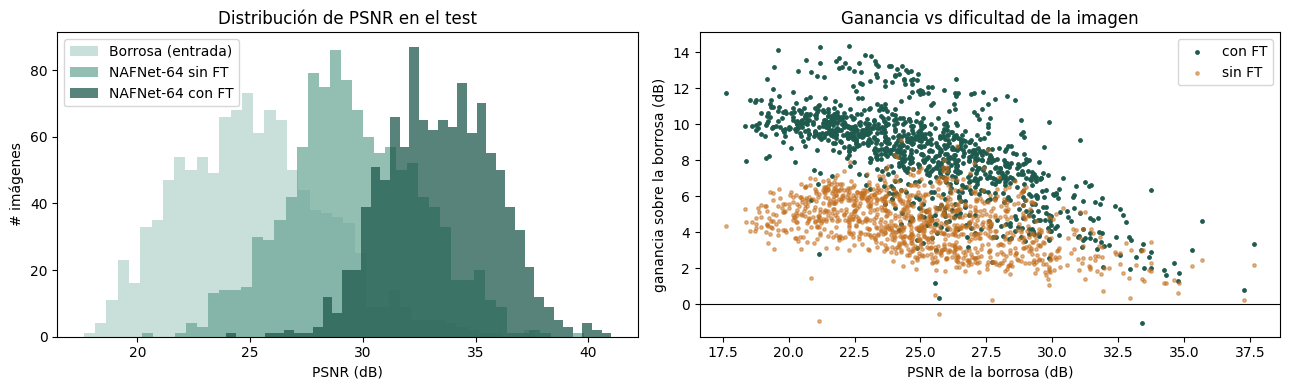

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, c in (("blur", "#b8d5ce"), ("base", "#6fa898"), ("ft", "#1f5a4e")):
    ax[0].hist(met[f"psnr_{k}"], bins=40, alpha=.75, color=c, label=labels[k])
ax[0].set(xlabel="PSNR (dB)", ylabel="# imágenes", title="Distribución de PSNR en el test"); ax[0].legend()
ax[1].scatter(met["psnr_blur"], met["psnr_ft"] - met["psnr_blur"], s=6, color="#1f5a4e", label="con FT")
ax[1].scatter(met["psnr_blur"], met["psnr_base"] - met["psnr_blur"], s=6, color="#c46f1e", alpha=.5, label="sin FT")
ax[1].axhline(0, color="k", lw=.8)
ax[1].set(xlabel="PSNR de la borrosa (dB)", ylabel="ganancia sobre la borrosa (dB)",
          title="Ganancia vs dificultad de la imagen"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Comparación con los intentos anteriores
Los modelos anteriores **no se vuelven a ejecutar** (código y checkpoints viejos, y partir de ruido aleatorio daría
salidas distintas). Sus **salidas guardadas** siguen en el historial del repositorio, así que se leen de ahí y se miden contra
las **imágenes originales del dataset** (las `sharp_*` que guardó `eval_comparativa.py`), exactamente igual que NAFNet:

- **DDPM v2** (commit `0ce381e`, `results/recon_*.png`): difusión condicional **desde ruido puro**, DDIM 100 pasos,
  10 imágenes a 640×360.
- **Zero-shot DeblurSDI** (commit `6ce6d78`, `results_gopro/recon_*.png`): kernel estimado por imagen, 5 imágenes a 256×256.

Desviación estándar con `ddof=0` (igual que `np.std` en `sample.py`).

> Nota: DDPM v2 y zero-shot se evaluaron a menor resolución y en pocas imágenes; la tabla de la sección 4.1 (NAFNet) es a 1280×720 en el test completo.

In [ ]:
import io, subprocess
from PIL import Image
from skimage.metrics import structural_similarity

def git_png(commit, path):
    # Lee un PNG de un commit anterior sin cambiar de rama
    data = subprocess.run(["git", "show", f"{commit}:{path}"], capture_output=True, check=True).stdout
    return np.array(Image.open(io.BytesIO(data)).convert("RGB"))

def leer(path):
    return np.array(Image.open(path).convert("RGB"))

def psnr8(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

def ssim8(a, b):
    return structural_similarity(a, b, channel_axis=2, data_range=255)

def evaluar(carpeta, n, otro_nombre, otro_commit, otro_patron):
    filas = []
    for i in range(n):
        gt = leer(f"{carpeta}/sharp_{i:04d}.png")
        imgs = {"Borrosa": leer(f"{carpeta}/blur_{i:04d}.png"),
                otro_nombre: git_png(otro_commit, otro_patron.format(i=i)),
                "NAFNet sin FT": leer(f"{carpeta}/nafnet_base_{i:04d}.png"),
                "NAFNet con FT": leer(f"{carpeta}/nafnet_ft_{i:04d}.png")}
        assert imgs[otro_nombre].shape == gt.shape, f"tamaño distinto en {i}: {imgs[otro_nombre].shape} vs {gt.shape}"
        fila = {"img": i}
        for k, im in imgs.items():
            fila[(k, "PSNR")] = psnr8(im, gt)
            fila[(k, "SSIM")] = ssim8(im, gt)
        filas.append(fila)
    df = pd.DataFrame(filas).set_index("img")
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    return df

def resumen(df):
    metodos = list(dict.fromkeys(m for m, _ in df.columns))
    return pd.DataFrame({
        "PSNR (dB)": [f"{df[(m, 'PSNR')].mean():.2f} ± {df[(m, 'PSNR')].std(ddof=0):.2f}" for m in metodos],
        "SSIM": [f"{df[(m, 'SSIM')].mean():.4f} ± {df[(m, 'SSIM')].std(ddof=0):.4f}" for m in metodos],
    }, index=metodos)

### 5.1 DDPM v2 - mismas 10 imágenes a 640×360

In [ ]:
D = f"{EVAL}/ddpm_640"
chk = [psnr8(git_png("0ce381e", f"results/sharp_{i:04d}.png"), leer(f"{D}/sharp_{i:04d}.png")) for i in range(10)]
print("PSNR entre la sharp de DDPM v2 y la del dataset (mín):", f"{min(chk):.1f} dB", "(inf = idénticas)")

ddpm = evaluar(D, 10, "DDPM v2", "0ce381e", "results/recon_{i:04d}.png")
display(ddpm.style.format(precision=4).format(precision=2, subset=pd.IndexSlice[:, [c for c in ddpm.columns if c[1] == "PSNR"]]))
print("\nMedia ± desviación (10 imágenes, 640×360):")
display(resumen(ddpm))
print("Referencia consola sample.py (oct): DDPM v2  PSNR 23.84 ± 1.52 dB | SSIM 0.8285 ± 0.0794")

PSNR entre la sharp de DDPM v2 y la del dataset (mín): 51.7 dB (inf = idénticas)



Media ± desviación (10 imágenes, 640×360):


,PSNR (dB),SSIM
Borrosa,27.70 ± 3.82,0.8890 ± 0.0984
DDPM v2,23.86 ± 1.51,0.8283 ± 0.0793
NAFNet sin FT,31.40 ± 3.35,0.9662 ± 0.0253
NAFNet con FT,36.06 ± 1.57,0.9815 ± 0.0089


Referencia consola sample.py (oct): DDPM v2  PSNR 23.84 ± 1.52 dB | SSIM 0.8285 ± 0.0794


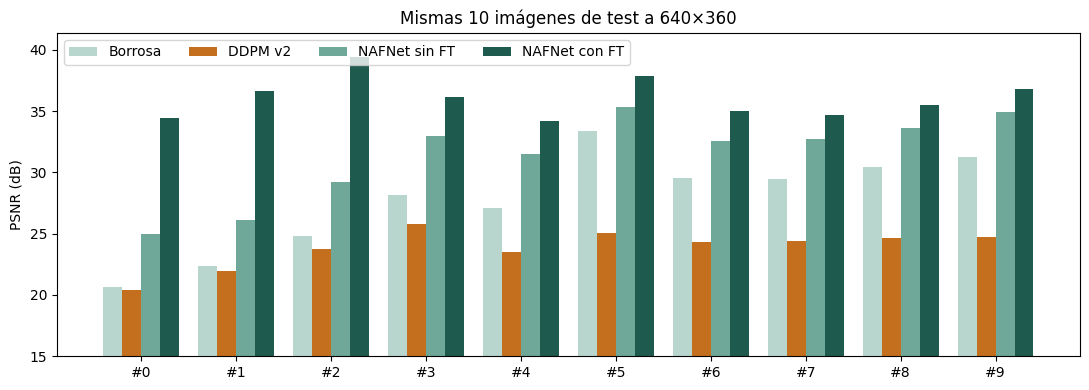

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
metodos = ["Borrosa", "DDPM v2", "NAFNet sin FT", "NAFNet con FT"]
colores = ("#b8d5ce", "#c46f1e", "#6fa898", "#1f5a4e")
x = np.arange(len(ddpm)); w = .2
for i, (m, c) in enumerate(zip(metodos, colores)):
    ax.bar(x + (i - 1.5) * w, ddpm[(m, "PSNR")], w, label=m, color=c)
ax.set_xticks(x); ax.set_xticklabels([f"#{i}" for i in ddpm.index])
ax.set(ylabel="PSNR (dB)", ylim=(15, None), title="Mismas 10 imágenes de test a 640×360")
ax.legend(ncol=4, loc="upper left"); plt.tight_layout(); plt.show()

### 5.2 Zero-shot DeblurSDI - mismas 5 imágenes a 256×256
(redimensionadas sin conservar proporción, como en el experimento original; la #3 colapsó a una imagen gris).

In [ ]:
Z = f"{EVAL}/zeroshot_256"
zs = evaluar(Z, 5, "Zero-shot", "6ce6d78", "results_gopro/recon_{i:04d}.png")
display(zs.style.format(precision=4).format(precision=2, subset=pd.IndexSlice[:, [c for c in zs.columns if c[1] == "PSNR"]]))
print("\nMedia ± desviación (5 imágenes, 256×256):")
display(resumen(zs))


Media ± desviación (5 imágenes, 256×256):


,PSNR (dB),SSIM
Borrosa,24.10 ± 2.48,0.8213 ± 0.0955
Zero-shot,10.38 ± 1.27,0.1945 ± 0.0893
NAFNet sin FT,28.31 ± 2.70,0.9517 ± 0.0241
NAFNet con FT,34.94 ± 1.97,0.9783 ± 0.0070


## 6. Resultados cualitativos
Borrosa | DDPM v2 | NAFNet sin FT | NAFNet con FT | nítida. Abajo, un recorte a resolución nativa para ver el detalle
(DDPM v2 solo existe a 640×360, así que su recorte se muestra ampliado ×2).

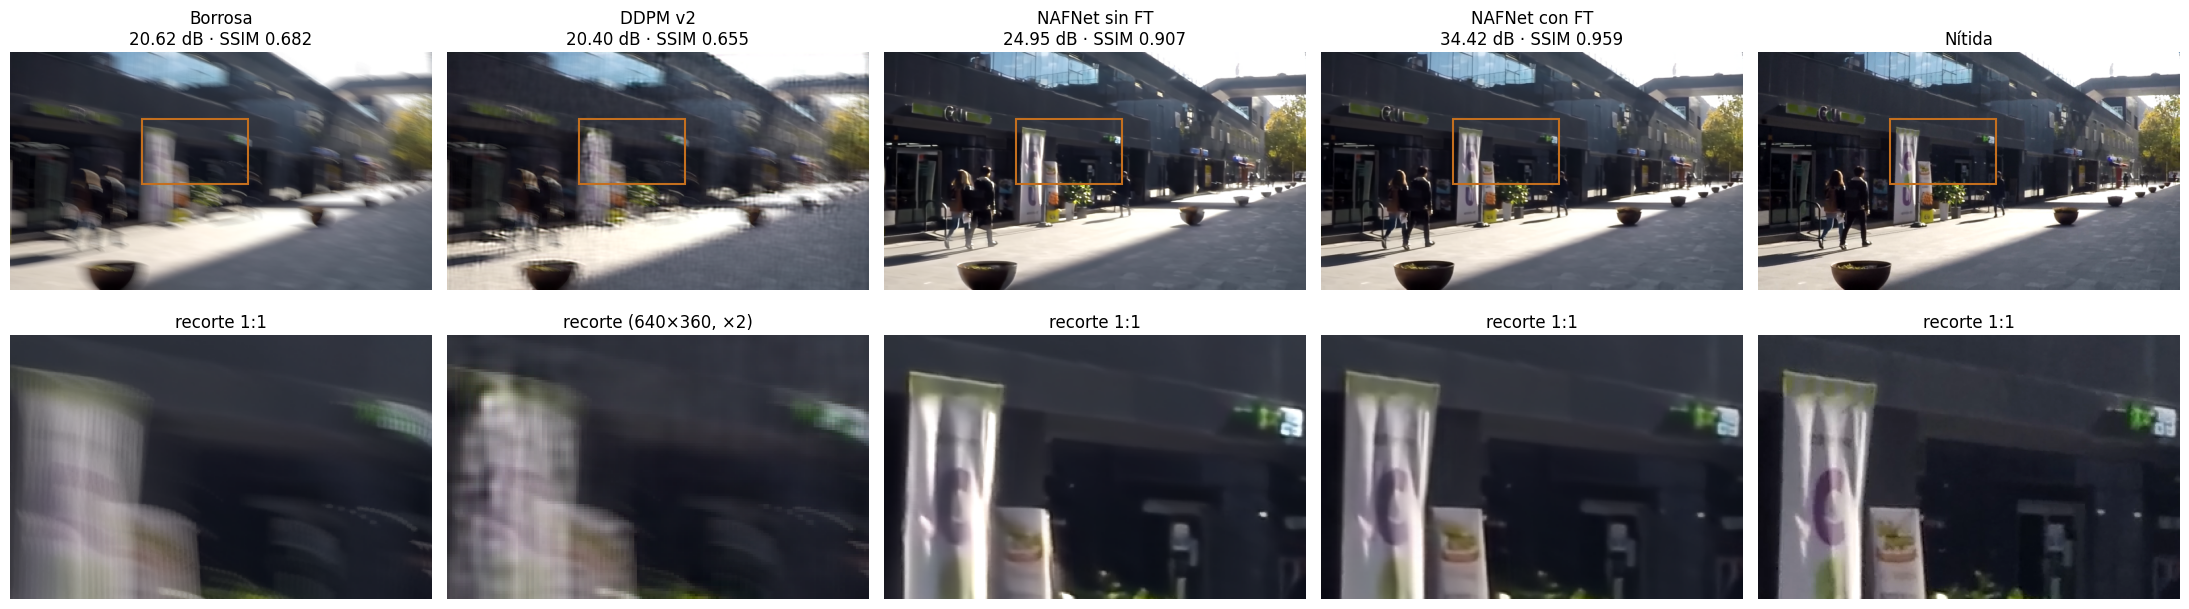

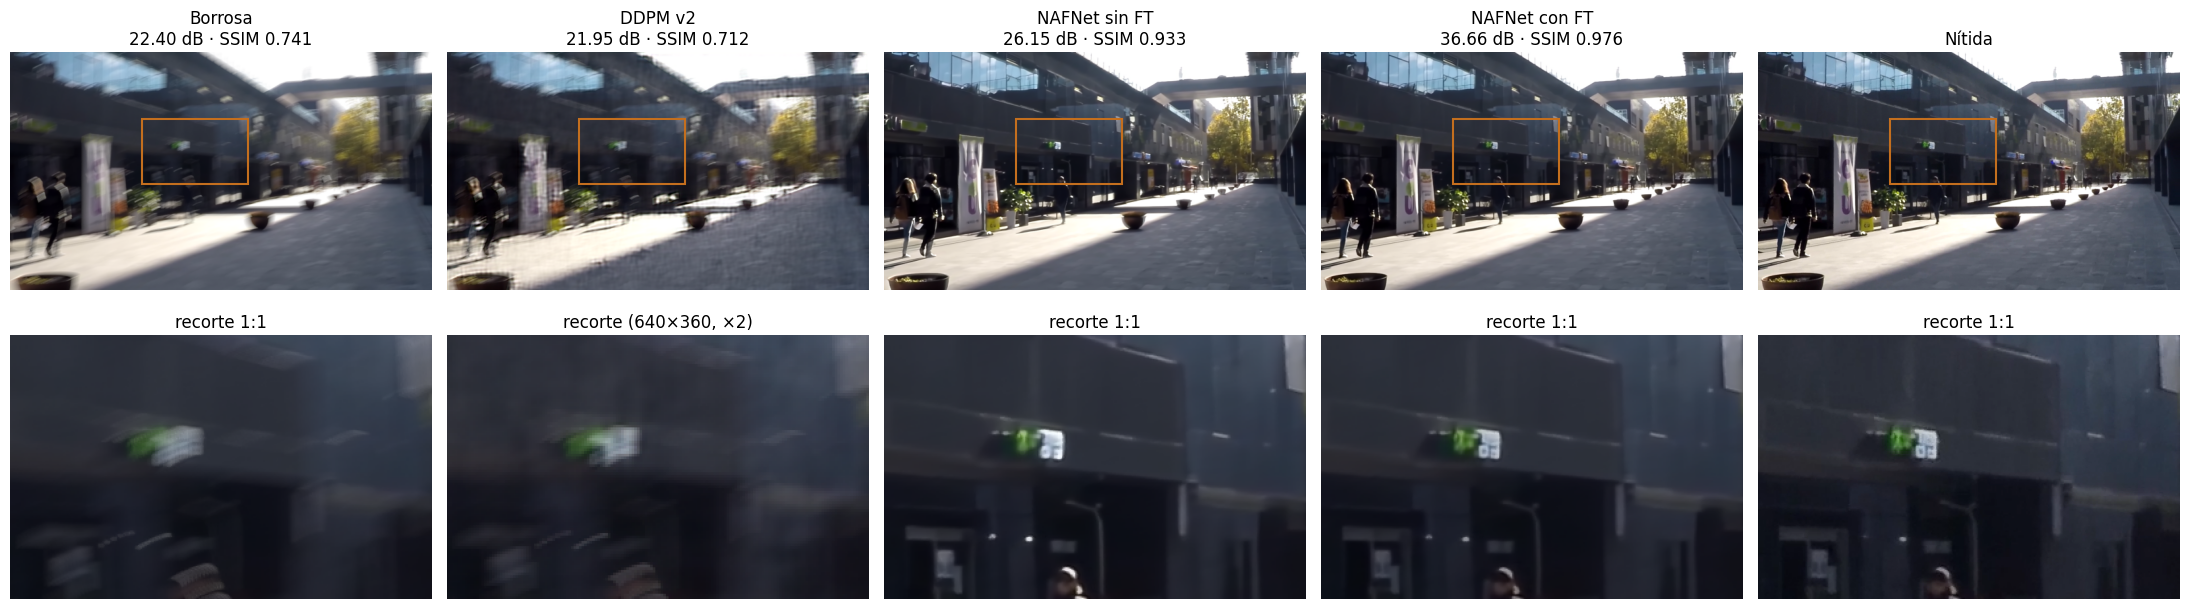

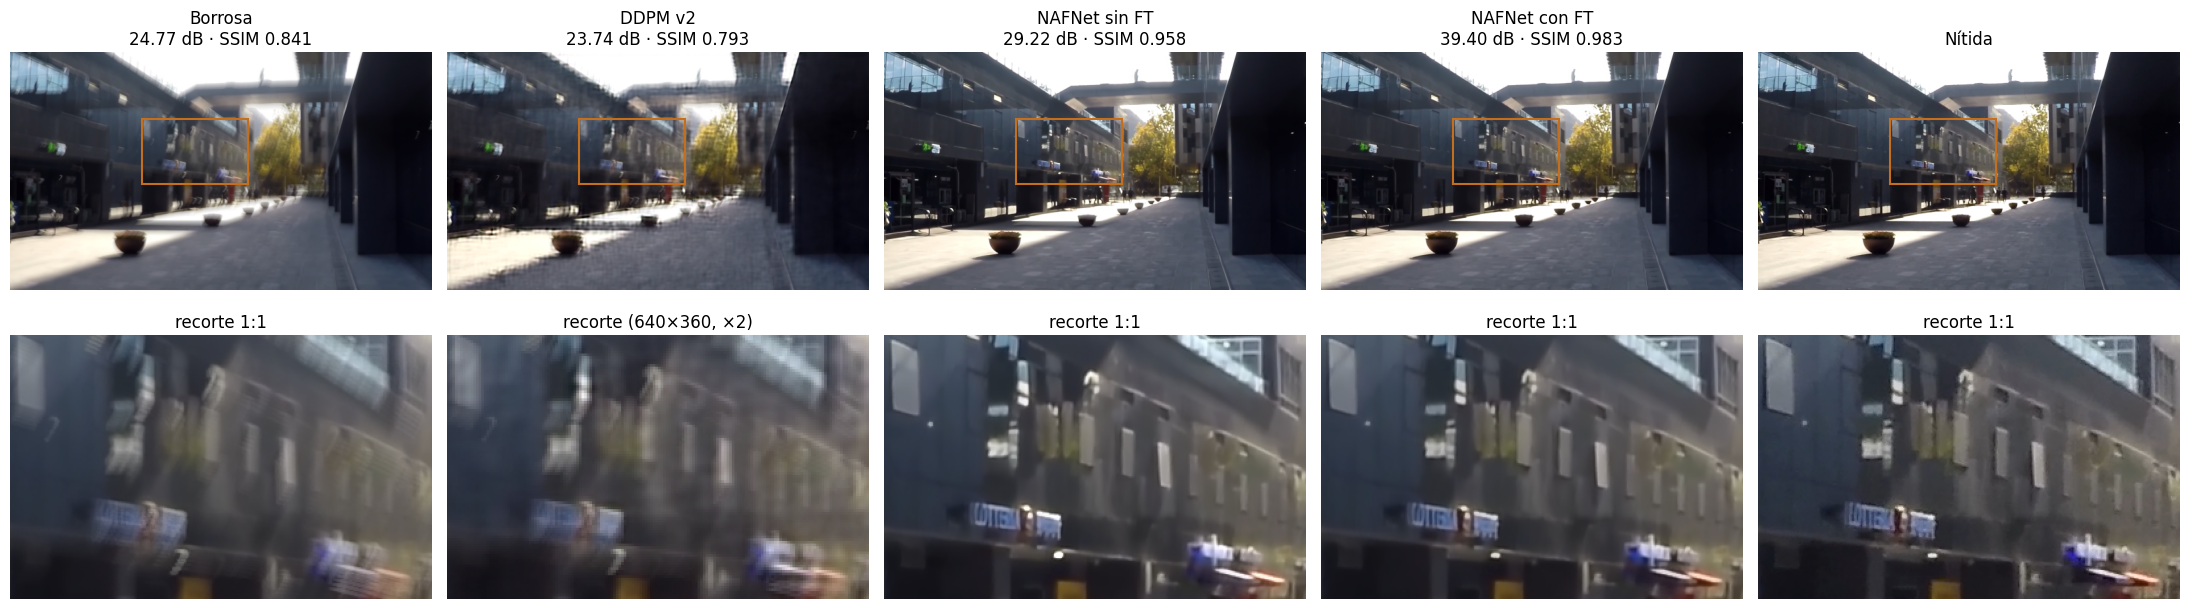

In [ ]:
cols = [("blur", "Borrosa"), ("ddpm", "DDPM v2"), ("nafnet_base", "NAFNet sin FT"),
        ("nafnet_ft", "NAFNet con FT"), ("sharp", "Nítida")]
nombre_df = {"blur": "Borrosa", "ddpm": "DDPM v2", "nafnet_base": "NAFNet sin FT", "nafnet_ft": "NAFNet con FT"}

def mostrar(i, crop=(400, 200, 320, 200)):   # (x, y, ancho, alto) del recorte en 1280x720
    x0, y0, cw, ch = crop
    fig, ax = plt.subplots(2, 5, figsize=(22, 6.5))
    for j, (k, t) in enumerate(cols):
        if k == "ddpm":
            im = git_png("0ce381e", f"results/recon_{i:04d}.png")
            rec = Image.fromarray(im[y0 // 2:(y0 + ch) // 2, x0 // 2:(x0 + cw) // 2]).resize((cw, ch), Image.NEAREST)
            rec, sub_rec = np.array(rec), "recorte (640×360, ×2)"
        else:
            im = leer(f"{D}/{k}_{i:04d}.png")
            rec, sub_rec = leer(f"{D}/full_{k}_{i:04d}.png")[y0:y0 + ch, x0:x0 + cw], "recorte 1:1"
        sub = ""
        if k in nombre_df:
            m = nombre_df[k]
            sub = f"\n{ddpm.loc[i, (m, 'PSNR')]:.2f} dB · SSIM {ddpm.loc[i, (m, 'SSIM')]:.3f}"
        ax[0, j].imshow(im); ax[0, j].set_title(t + sub)
        ax[0, j].add_patch(plt.Rectangle((x0 / 2, y0 / 2), cw / 2, ch / 2, fill=False, ec="#c46f1e", lw=1.5))
        ax[1, j].imshow(rec); ax[1, j].set_title(sub_rec)
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()

for i in range(3): # cambiar el rango o el crop para explorar otras imágenes
    mostrar(i)

Las mismas imágenes del intento zero-shot (256×256, sin conservar proporción, como en el experimento original):

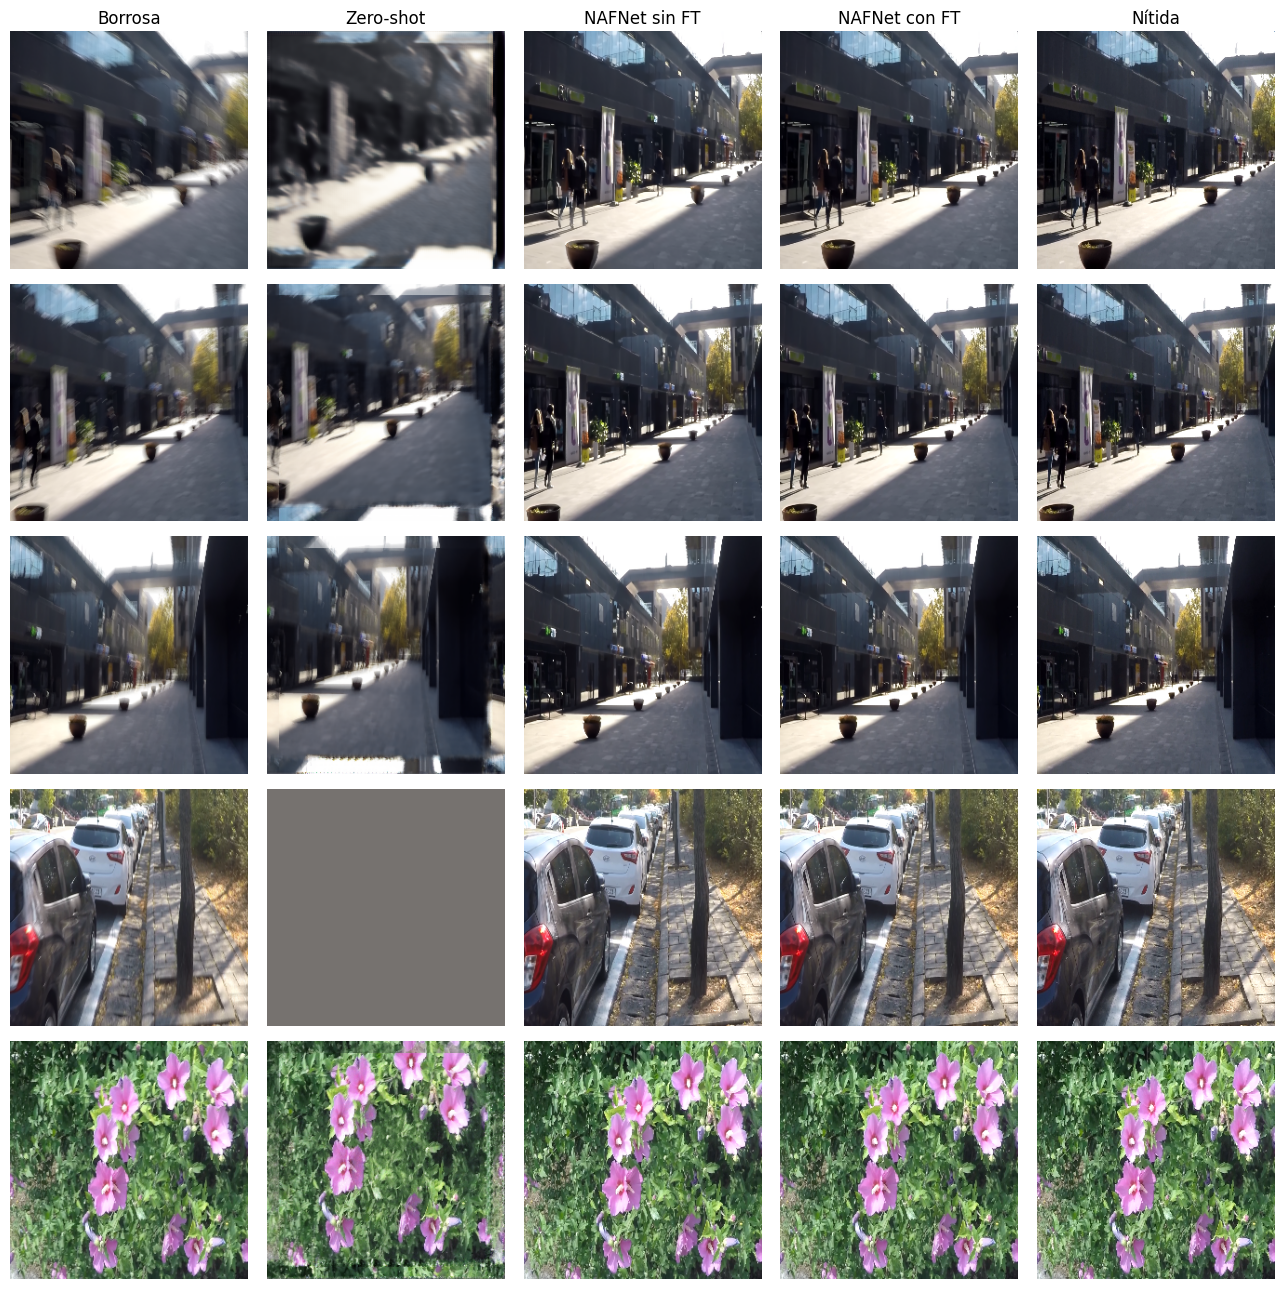

In [ ]:
cols_z = [("blur", "Borrosa"), ("zs", "Zero-shot"), ("nafnet_base", "NAFNet sin FT"),
          ("nafnet_ft", "NAFNet con FT"), ("sharp", "Nítida")]
fig, ax = plt.subplots(5, 5, figsize=(13, 13))
for i in range(5):
    for j, (k, t) in enumerate(cols_z):
        im = git_png("6ce6d78", f"results_gopro/recon_{i:04d}.png") if k == "zs" else leer(f"{Z}/{k}_{i:04d}.png")
        ax[i, j].imshow(im); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(t)
plt.tight_layout(); plt.show()

### Guardar resultados

In [ ]:
# Tablas de la sección 5 dentro del zip, junto con las de eval_comparativa.py
ddpm.to_csv(f"{EVAL}/comparacion_ddpm_640.csv")
zs.to_csv(f"{EVAL}/comparacion_zeroshot_256.csv")
resumen(ddpm).to_csv(f"{EVAL}/resumen_ddpm_640.csv")
resumen(zs).to_csv(f"{EVAL}/resumen_zeroshot_256.csv")
import shutil
shutil.make_archive("eval_comparativa", "zip", EVAL)

from google.colab import files
files.download("eval_comparativa.zip")
# Alternativa: copiar a Drive
# from google.colab import drive; drive.mount("/content/drive")
# !cp eval_comparativa.zip /content/drive/MyDrive/IA2/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Conclusiones y próximos pasos
- **DDPM v2 desde ruido** empeoró las 10 imágenes (ver 5.1; en octubre: 23.84 dB vs ~27.7 de la borrosa): generar la
  imagen completa desde ruido con pocos datos y baja resolución se estanca en ~24-25 dB y pierde detalle.
- **Zero-shot DeblurSDI**: un kernel por imagen, muy lento e inestable (una de las 5 colapsó).
- **NAFNet-64 con fine-tuning** es un predictor determinista fuerte, pues en validación pasó de 29.20 a 35.12 dB (+5.9);
  ver sección 4 para el número limpio en el test.
- **Entrega final:** DDPM condicional que aprende solo el **residuo** $r = x - \hat{y}$, condicionado en
  $[y, \hat{y}]$, con muestreo truncado desde $\hat{y}$ ruidoso en $t_0$ - el residuo es pequeño y de alta frecuencia,
  así que la difusión solo tiene que añadir detalle en vez de reconstruir toda la imagen. `precompute_nafnet.py` ya deja
  calculadas las predicciones $\hat{y}$ y las estadísticas del residuo para normalizarlo.